In [1]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = "0"
import scanpy as sc
import seaborn as sns
from tqdm import tqdm
import numpy as np
import pandas as pd
from collections import Counter,defaultdict

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import autocast, GradScaler

from dataprocess.h5a import H5ADTokenizer
from dataprocess.genepep import GenePepExtractor
from model.const import set_species_context
from model import data
import model.resa as resa
import model.utils as utils
import model.mmd as mmd
import model.lr_schedule as lr_sche

In [ ]:
organ='motor'
species_to_adata = {
    "homo_sapiens": sc.read_h5ad(f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/scrna/{organ}/homo_sapiens.h5ad"),
    "Mus_musculus": sc.read_h5ad(f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/scrna/{organ}/Mus_musculus.h5ad"),
    "Macaca_mulatta": sc.read_h5ad(f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/scrna/{organ}/Macaca_mulatta.h5ad"),
    "Callithrix_jacchus": sc.read_h5ad(f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/scrna/{organ}/Callithrix_jacchus.h5ad"),
}

In [3]:
species_to_embed_file = {
    "homo_sapiens": f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/esm_embedding/{organ}/homo_sapiens.avg.embeddings",
    "Mus_musculus": f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/esm_embedding/{organ}/Mus_musculus.avg.embeddings",
    "Macaca_mulatta": f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/esm_embedding/{organ}/Macaca_mulatta.avg.embeddings",
    "Callithrix_jacchus": f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/esm_embedding/{organ}/Callithrix_jacchus.avg.embeddings",
}

In [4]:
species_dict=set_species_context(species_to_adata)
token_species_dict={v:k for k,v in species_dict.items()}

In [5]:
tokenized = H5ADTokenizer(
    species_to_adata,
    species_to_embed_file,
).process_species_adata()

100%|██████████| 34310/34310 [00:02<00:00, 15665.16it/s]


In [6]:
species_to_reps = {
    "homo_sapiens": "X_pca",
    "Mus_musculus": "X_pca",
    "Macaca_mulatta": "X_pca",
    "Callithrix_jacchus": "X_pca",
}

In [7]:
train_loader, test_loader = data.prepare_multispecies_dataloaders(
    tokenized,
    batch_size=512,
    species_to_reps=species_to_reps,
    batch_species=4,
)

homo_sapiens: X_pca
Mus_musculus: X_pca
Macaca_mulatta: X_pca
Callithrix_jacchus: X_pca


In [8]:
for batch in test_loader:
    input_ids,adata,sp=batch
    print(input_ids)
    print(adata)
    print(sp)
    break

tensor([[   2,  457, 1861,  ...,    0,    0,    0],
        [   2, 1404, 2110,  ...,    0,    0,    0],
        [   2,   84, 1581,  ...,    0,    0,    0],
        ...,
        [   2,  592, 1861,  ...,    0,    0,    0],
        [   2, 1351, 1861,  ...,    0,    0,    0],
        [   2, 2165, 1861,  ...,    0,    0,    0]])
tensor([[ 17.8391,  11.3704,  -1.0757,  ...,  -1.2461,  -1.5221,   1.6135],
        [ 17.9448,  11.6815,   1.4746,  ...,   0.5147,  -0.4216,   0.0408],
        [-13.4024,  -2.6059,  -1.8522,  ...,   0.3843,   0.3396,   2.2280],
        ...,
        [ 19.0589,   6.8614,  -0.3746,  ...,   0.7395,  -0.6743,   0.2105],
        [-18.6196,  10.4404,   4.9787,  ...,  -0.7140,   0.6870,   0.0652],
        [ 16.1081,   7.7850,  -1.1799,  ...,  -0.0954,   0.2121,   0.9335]])
tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

In [9]:
d_model=120
scale=4
input_size=50
latent_size=64
num_layers=1
n_clusters=100000
net=resa.ReSA(species_to_embed_file,d_model,input_size,latent_size,num_layers,n_clusters,scale=scale,)

In [10]:
def train_epoch(net,train_loader,loss_fn,loss_fn1,optimizer,scaler,device,current_temp,scheduler,ml_weight=1.0):
    net.train()
    metrics=utils.Accumulator(4)
    pbar=tqdm(train_loader,desc='Processing')
    for _,batch in enumerate(pbar):
        optimizer.zero_grad(set_to_none=True)

        data,adata,sp=batch
        data = data.to(device, non_blocking=True)
        adata = adata.float().to(device, non_blocking=True)
        sp = sp.to(device, non_blocking=True)

        with autocast('cuda'):
            sl = torch.tensor(0.0, device=device)
            protein_features,gene_features,logit_scale=net(adata,data,sp,)
            species_ids = torch.unique(sp).tolist()
            #for i in torch.unique(sp):
            for s in species_ids:
                mask = (sp == s)

                indices = torch.nonzero(mask).squeeze(1)
                protein_features_i = torch.index_select(protein_features, 0, indices)
                gene_features_i = torch.index_select(gene_features, 0, indices)
                sl += loss_fn(protein_features_i, gene_features_i, logit_scale,)
            ml=loss_fn1(protein_features,sp)
            loss=sl+ml*ml_weight

        scaler.scale(loss).backward()
        if net.transformer.embed.gene_embed.weight.grad is not None:
            #net.transformer.embed.gene_embed.weight.grad[3:-1] = 0
            net.transformer.embed.gene_embed.weight.grad[4:] = 0
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        if scheduler:
            scheduler.step()
        lr=optimizer.param_groups[0]['lr']
        pbar.set_description(f"loss:{loss.detach().item():.4f},sl:{sl.detach().item():.8f},ml:{ml.detach().item():.8f},lr:{lr:.8f}")
        metrics.add(loss.detach().item() * len(sp), sl.detach().item() * len(sp),ml.detach().item() * len(sp), len(sp))

    return {'loss':metrics[0] / metrics[3],'sl':metrics[1] / metrics[3],'ml':metrics[2] / metrics[3],}

def train(net,train_loader,test_loader,epochs,lr,species_to_h5,net_path,temp,ml_weight):
    def init_weights(m):
        if type(m) == nn.Linear or type(m) == nn.Conv1d:
            nn.init.xavier_uniform_(m.weight)
    net.apply(init_weights)
    print('init done')

    device =torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('training on', device)
    net.to(device)

    loss_fn=resa.MultiScaleReSALoss()#swav.ATACKNNLoss()#
    loss_fn1=mmd.MMMD(kernel_type='rbf',each=True)#mmd.MSampleLoss(each=True)#
    optimizer = torch.optim.AdamW(net.parameters(), lr=lr,fused=True)
    scheduler = lr_sche.CosineAnnealingWarmupRestarts(
        optimizer,
        first_cycle_steps=2000,   # 一个周期 2000 batch
        cycle_mult=1,             # 不增加周期长度
        max_lr=lr*1.5,            # 最大 lr 稍高
        min_lr=1e-6,
        warmup_steps=400,         # 前 400 batch 线性升到 max_lr
        gamma=0.6
    )
    early_stopping = utils.EarlyStopping(
        patience=10,               # 连续5个epoch指标不提升就停止
        verbose=True, 
        path=net_path, # 保存的文件名
        mode='min'                # 如果监控的是准确率，这里改用 'max'
    )
    scaler = GradScaler('cuda')
    cr_ml_weight=0.0
    warm_epoch=5
    try:
        for epoch in range(epochs):
            print(f"epoch:{epoch},")
            print(f"Temp: {temp}")
            if epoch>=warm_epoch:
                cr_ml_weight=ml_weight
            losses=train_epoch(net,train_loader,loss_fn,loss_fn1,optimizer,scaler,device,temp,scheduler,cr_ml_weight)
            current_lr = optimizer.param_groups[0]['lr']
            print(f"lr:{current_lr},")
            print(f'{losses}')
            if epoch>=warm_epoch:
                early_stopping(losses['loss'],net)
                if early_stopping.early_stop:
                    print("====== Early stopping triggered! ======")
                    #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
                    break
            if epoch ==epochs-1:
                torch.save(net.state_dict(), net_path)
                print(f'saving weight in {net_path}')
                #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
                break
    except KeyboardInterrupt:
        #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
        torch.save(net.state_dict(), net_path)
        print(f'saving weight in {net_path}')

In [11]:
net_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/pth/ReSA_{organ}.pth'
species_to_h5=tokenized
epochs=100
lr=1e-3
#train(net,train_loader,test_loader,epochs,lr,species_to_h5,net_path,temp=0.2,ml_weight=0.0)

In [12]:
net_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/pth/ReSA_{organ}.pth'
net.load_state_dict(torch.load(net_path,weights_only=True))

<All keys matched successfully>

old
computing PCA
    with n_comps=25
    finished (0:00:00)
Running MOT_Correction by 'inferred_species' -> adata.obsm['X_mot']
X_mot shape: (157424, 25)
computing neighbors


/mnt/public5/panguanyu/environment/mconda3/miniconda3/envs/crs_env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:01:01)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:02:10)


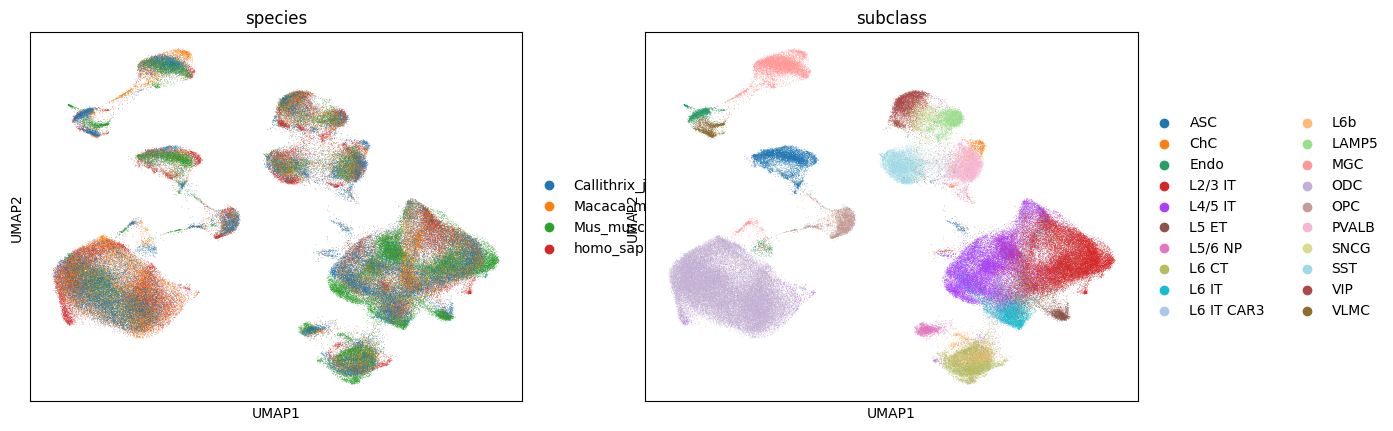

In [13]:
import importlib
import model.evaluate
importlib.reload(model.evaluate)
from model.evaluate import evaluate_integration

integrated_adata = evaluate_integration(
    net,
    test_loader,
    species_to_adata=tokenized,
    #metadata_columns=["cluster"],
    # 如果不同物种列名不一样，改用：
     species_to_metadata_columns={
         "one":["subclass",],
         "homo_sapiens": ["subclass",],
         "Mus_musculus": ["subclass", ],
         "Macaca_mulatta": ["subclass", ],
         "Callithrix_jacchus": ["subclass", ],
     },
    embedding="protein",
    use_mot_correction=True,
    correction_by="inferred_species",
    correction_kwargs={
        "max_rounds": 10,
        "n_clusters": 100,
        "assignment_mode": "sinkhorn",
    },
    umap_colors=["species", "subclass"],
    comatrix_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/comatrix/{organ}.npz',
)

In [14]:
integrated_adata

AnnData object with n_obs × n_vars = 157424 × 64
    obs: 'species', 'subclass', 'inferred_species_token', 'inferred_species'
    uns: 'pca', 'neighbors', 'umap', 'species_colors', 'subclass_colors'
    obsm: 'X_pca', 'X_mot', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [15]:
species_key = "species"
celltype_key = "subclass"

target_species = [
    "homo_sapiens",
    "Mus_musculus",
    "Macaca_mulatta",
    "Callithrix_jacchus",
]

obs = integrated_adata.obs

# 每个物种包含的细胞类型
celltypes_by_species = {
    species: set(
        obs.loc[obs[species_key] == species, celltype_key]
        .dropna()
        .astype(str)
    )
    for species in target_species
}

# 所有目标物种共有的细胞类型
common_celltypes = sorted(
    set.intersection(*(celltypes_by_species.values()))
)

print(f"共有细胞类型数量：{len(common_celltypes)}")
print(common_celltypes)

共有细胞类型数量：20
['ASC', 'ChC', 'Endo', 'L2/3 IT', 'L4/5 IT', 'L5 ET', 'L5/6 NP', 'L6 CT', 'L6 IT', 'L6 IT CAR3', 'L6b', 'LAMP5', 'MGC', 'ODC', 'OPC', 'PVALB', 'SNCG', 'SST', 'VIP', 'VLMC']


In [16]:
celltypes_by_species

{'homo_sapiens': {'ASC',
  'ChC',
  'Endo',
  'L2/3 IT',
  'L4/5 IT',
  'L5 ET',
  'L5/6 NP',
  'L6 CT',
  'L6 IT',
  'L6 IT CAR3',
  'L6b',
  'LAMP5',
  'MGC',
  'ODC',
  'OPC',
  'PVALB',
  'SNCG',
  'SST',
  'VIP',
  'VLMC'},
 'Mus_musculus': {'ASC',
  'ChC',
  'Endo',
  'L2/3 IT',
  'L4/5 IT',
  'L5 ET',
  'L5/6 NP',
  'L6 CT',
  'L6 IT',
  'L6 IT CAR3',
  'L6b',
  'LAMP5',
  'MGC',
  'ODC',
  'OPC',
  'PVALB',
  'SNCG',
  'SST',
  'VIP',
  'VLMC'},
 'Macaca_mulatta': {'ASC',
  'ChC',
  'Endo',
  'L2/3 IT',
  'L4/5 IT',
  'L5 ET',
  'L5/6 NP',
  'L6 CT',
  'L6 IT',
  'L6 IT CAR3',
  'L6b',
  'LAMP5',
  'MGC',
  'ODC',
  'OPC',
  'PVALB',
  'SNCG',
  'SST',
  'VIP',
  'VLMC'},
 'Callithrix_jacchus': {'ASC',
  'ChC',
  'Endo',
  'L2/3 IT',
  'L4/5 IT',
  'L5 ET',
  'L5/6 NP',
  'L6 CT',
  'L6 IT',
  'L6 IT CAR3',
  'L6b',
  'LAMP5',
  'MGC',
  'ODC',
  'OPC',
  'PVALB',
  'SNCG',
  'SST',
  'VIP',
  'VLMC'}}

In [17]:
#integrated_adata.write('/mnt/public5/panguanyu/cross_species/code/sypy/umap_results/figure4/motor/hresa_motor_1_64_1.h5ad')

In [18]:
#adata=sc.read_h5ad('/mnt/public5/panguanyu/cross_species/code/sypy/umap_results/figure4/motor/hresa_motor_1_64_1.h5ad')

In [19]:
#adata

In [20]:
def attention_score_topk_freq(
    net,
    dataset,
    indices,
    device,
    species_to_embed_file,
    chosen_species,
    csv_path,
    top_k=10,
    top_n=10,
):
    net.eval()
    net.to(device)

    gene_freq = defaultdict(int)

    net.transformer.embed.gene_id(species_to_embed_file)
    raw_map = net.transformer.embed.species_gene_id_map[chosen_species]
    token_to_gene_name = {v: k for k, v in raw_map.items()}

    with torch.no_grad():
        for i in tqdm(indices):

            input_ids = dataset[i]['input_ids'].unsqueeze(0).to(device)
            sp = dataset[i]['sp'].unsqueeze(0).to(device)

            with autocast('cuda'):
                attn_score = net.transformer.attn_score(input_ids, sp)

            attn_score = attn_score.cpu().numpy()[0]   # [L, L]
            input_tokens = input_ids.cpu().numpy()[0]       # [L]

            # column importance: [L]
            cell_gene_importance = attn_score.mean(axis=0)

            # top-k indices
            topk_idx = np.argsort(cell_gene_importance)[-top_k:][::-1]

            for idx in topk_idx:
                token_id = input_tokens[idx]
                if token_id <= 3:
                    continue

                gene_name = token_to_gene_name.get(token_id, f"Unknown_{token_id}")
                gene_freq[gene_name] += 1

    # normalize to frequency
    n_cells = len(indices)
    final_scores = {
        gene: freq / n_cells
        for gene, freq in gene_freq.items()
    }

    sorted_genes = sorted(final_scores.items(), key=lambda x: x[1], reverse=True)

    '''#top_n = 10
    print(f"\nTop {top_n} Genes by Top-{top_k} Attention Frequency:")

    top_genes=[]
    for rank, (gene, score) in enumerate(sorted_genes[:top_n]):
        print(f"Rank {rank+1}: {gene} (Freq: {score:.4f})")
        top_genes.append(gene)
    
    print(top_genes)'''
    df = pd.DataFrame(sorted_genes, columns=["gene", "score"])
    df.to_csv(csv_path, index=False)

    return sorted_genes[:top_n]

In [21]:
'''import re

cell_type_column = 'subclass'
output_dir = '/mnt/public5/panguanyu/cross_species/gefor/code/tfc'
top_k = 20
top_n = 30
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs(output_dir, exist_ok=True)

all_top_results = []
result_manifest = []

for chosen_species, adata in tokenized.items():
    if cell_type_column not in adata.obs.columns:
        print(f'Skip {chosen_species}: obs 中没有 {cell_type_column!r} 列')
        continue

    x_rep = species_to_reps.get(chosen_species, 'X_pca')
    dataset = data.AnndataFastDataset(adata, chosen_species, X_rep=x_rep)
    cell_type_to_indices = defaultdict(list)
    for cell_index, cell_type in enumerate(adata.obs[cell_type_column].tolist()):
        if pd.notna(cell_type):
            cell_type_to_indices[str(cell_type)].append(cell_index)

    for cell_type, indices in tqdm(
        cell_type_to_indices.items(),
        total=len(cell_type_to_indices),
        desc=f'{chosen_species} cell types',
    ):

        safe_cell_type = re.sub(r'[^0-9A-Za-z._-]+', '_', cell_type).strip('_')
        safe_cell_type = safe_cell_type or 'unnamed'
        csv_path = os.path.join(
            output_dir,
            f'{organ}_{chosen_species}_{safe_cell_type}.csv',
        )

        top_results = attention_score_topk_freq(
            net,
            dataset,
            indices,
            device,
            species_to_embed_file,
            chosen_species,
            csv_path,
            top_k=top_k,
            top_n=top_n,
        )

        result_manifest.append({
            'species': chosen_species,
            'cell_type': cell_type,
            'n_cells': len(indices),
            'csv_path': csv_path,
        })
        all_top_results.extend(
            {
                'species': chosen_species,
                'cell_type': cell_type,
                'rank': rank,
                'gene': gene,
                'score': score,
                'n_cells': len(indices),
            }
            for rank, (gene, score) in enumerate(top_results, start=1)
        )

manifest_path = os.path.join(output_dir, f'{organ}_attention_score_topk_freq_manifest.csv')
summary_path = os.path.join(output_dir, f'{organ}_attention_score_topk_freq_top{top_n}.csv')
pd.DataFrame(result_manifest).to_csv(manifest_path, index=False)
pd.DataFrame(all_top_results).to_csv(summary_path, index=False)
print(f'完成 {len(result_manifest)} 个物种-细胞类型组合')
print(f'清单已保存到: {manifest_path}')
print(f'Top-{top_n} 汇总已保存到: {summary_path}')
pd.DataFrame(result_manifest)'''

"import re\n\ncell_type_column = 'subclass'\noutput_dir = '/mnt/public5/panguanyu/cross_species/gefor/code/tfc'\ntop_k = 20\ntop_n = 30\ndevice = torch.device('cuda' if torch.cuda.is_available() else 'cpu')\nos.makedirs(output_dir, exist_ok=True)\n\nall_top_results = []\nresult_manifest = []\n\nfor chosen_species, adata in tokenized.items():\n    if cell_type_column not in adata.obs.columns:\n        print(f'Skip {chosen_species}: obs 中没有 {cell_type_column!r} 列')\n        continue\n\n    x_rep = species_to_reps.get(chosen_species, 'X_pca')\n    dataset = data.AnndataFastDataset(adata, chosen_species, X_rep=x_rep)\n    cell_type_to_indices = defaultdict(list)\n    for cell_index, cell_type in enumerate(adata.obs[cell_type_column].tolist()):\n        if pd.notna(cell_type):\n            cell_type_to_indices[str(cell_type)].append(cell_index)\n\n    for cell_type, indices in tqdm(\n        cell_type_to_indices.items(),\n        total=len(cell_type_to_indices),\n        desc=f'{chosen_spec

In [22]:
from torch.utils.data import DataLoader
import numpy as np
from model.mot_correction import load_comatrix
def gene_embed_cell_color(species_to_embed_file,species_genes,species_to_dataset,net,device,batch_size,comatrix_path):
    net.transformer.embed.gene_id(species_to_embed_file)
    net.to(device)
    net.eval()
    #assert set(species_genes.keys())==set(species_to_dataset.keys())
    embeddings=[]
    gene_list=[]
    cells=[]
    sps=[]
    for species in species_genes:
        genes=species_genes[species]
        gene_tokens=[net.transformer.embed.species_gene_id_map[species][gene] for gene in genes]
        raw_map=net.transformer.embed.species_gene_id_map[species]
        token_to_gene_name = {v: k for k, v in raw_map.items()}
        dataset=species_to_dataset[species]
        test_loader=DataLoader(dataset,batch_size=batch_size,shuffle=False,collate_fn=data.h5labelcollate_fn,)

        pbar=tqdm(test_loader,desc='Processing')
        for i,batch in enumerate(pbar):
            with torch.no_grad():
                input_ids,adata,sp,y=batch
                adata=adata.to(device, non_blocking=True)
                input_ids=input_ids.to(device, non_blocking=True)
                sp = sp.to(device, non_blocking=True)
                with autocast('cuda'):
                    attn_embeddings=net.contextual_embed(input_ids,sp)
                batch_embeddings = []
                batch_gene=[]
                batch_cells=[]
                batch_sps=[]
                for gene_token in gene_tokens:
                    token_pos=(input_ids==gene_token)
                    for b in range(input_ids.shape[0]):
                        pos = token_pos[b]
                        emb = attn_embeddings[b][pos]
                        H = attn_embeddings.shape[2]
                        if emb.shape[0] == 0:
                            batch_embeddings.append(torch.zeros(H, device=device))
                        else:
                            batch_embeddings.append(emb.mean(0))
                        batch_cells.append(int(y[b]))
                        batch_gene.append(token_to_gene_name[gene_token])
                        batch_sps.append(token_species_dict[int(sp[b])])
                token_embeddings = torch.stack(batch_embeddings, dim=0)
            embeddings.append(token_embeddings.cpu())
            gene_list+=batch_gene
            cells+=list(test_loader.dataset.le.inverse_transform(batch_cells))
            sps+=batch_sps
    embeddings=torch.cat(embeddings,dim=0)
    #embeddings=F.normalize(embeddings,p=2,dim=1).numpy()
    embeddings=embeddings.numpy()
    types=['gene']*len(embeddings)

    
    adata=sc.AnnData(embeddings)
    adata.obs['cell_type']=cells
    adata.obs['gene']=gene_list
    adata.obs['sp']=sps
    print(adata.shape)
    mask = ~(np.all(adata.X == 0, axis=1))  # True 表示不是全零
    adata = adata[mask].copy()  # 保留非全零的行
    adata.obsm['X_pca_harmony']=load_comatrix(comatrix_path,adata.X.T,adata.obs['sp'])
    print(adata.shape)
    sc.pp.neighbors(adata, use_rep='X_pca_harmony')
    sc.tl.umap(adata)
    n = adata.obs['cell_type'].nunique()
    colors = sns.color_palette("tab20") + sns.color_palette("tab20b") + sns.color_palette("tab20c")
    colors = colors[:n]
    return adata
    

In [23]:
'''species_genes={
    'homo_sapiens':['EGFR','MAF'],
    'Mus_musculus':['Egfr','Maf'],
    'Macaca_mulatta':['EGFR','MAF'],
    'Callithrix_jacchus':['EGFR','MAF'],
}'''
species_genes={
    'homo_sapiens':['ERBB4'],
    'Mus_musculus':['Erbb4'],
    'Macaca_mulatta':['ERBB4'],
    'Callithrix_jacchus':['ERBB4'],
}
gene_cell_column='subclass'
species_to_dataset={}
for species,adata in species_to_adata.items():
    if species in species_genes:
        print(f"loading {species}")
        #adata=sc.read_h5ad(h5_file)
        species_to_dataset[species]=data.AnndataLabelDataset(adata,species,cell_column=gene_cell_column,X_rep='X_pca')

device =torch.device('cuda' if torch.cuda.is_available() else 'cpu')

loading homo_sapiens
loading Mus_musculus
loading Macaca_mulatta
loading Callithrix_jacchus


In [25]:
gene_adata=gene_embed_cell_color(species_to_embed_file,species_genes,species_to_dataset,net,device,
            batch_size=64,comatrix_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/comatrix/{organ}.npz')

Processing: 100%|██████████| 537/537 [00:09<00:00, 54.79it/s]


(157424, 64)
(79682, 64)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:10)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:59)


In [ ]:
gene_adata.obs['gene']=[g.upper() for g in gene_adata.obs['gene']]

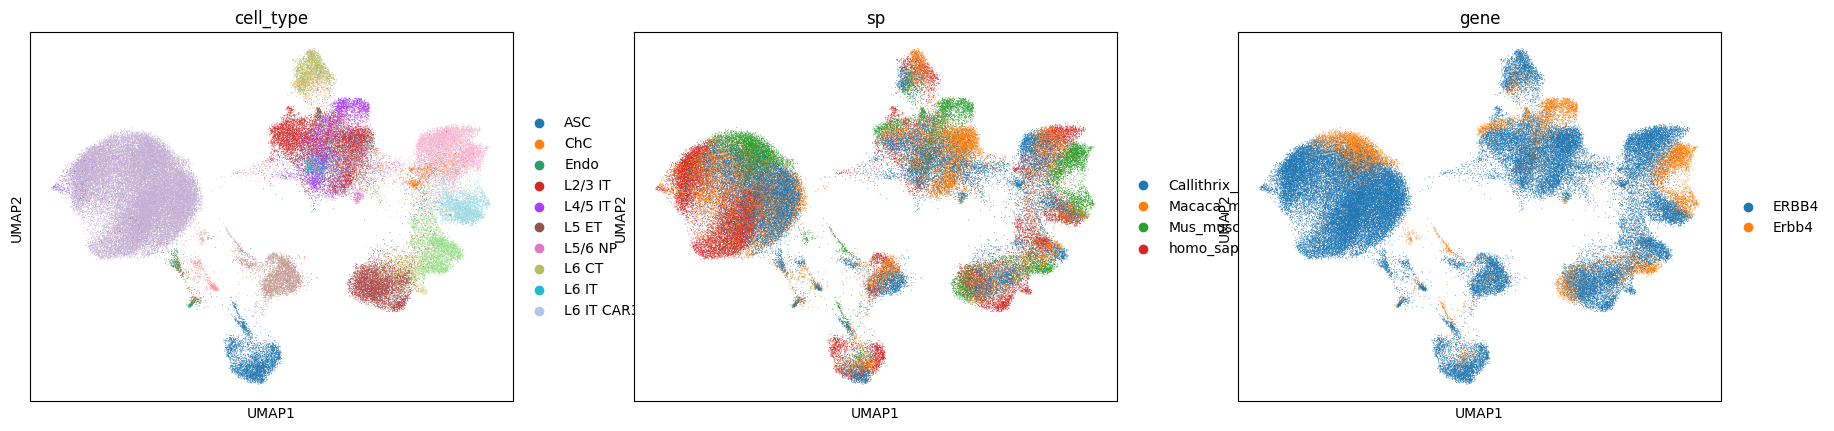

In [26]:
sc.pl.umap(gene_adata,color=['cell_type','sp','gene'])

In [ ]:
gene_adata.write('/mnt/public5/panguanyu/cross_species/gefor/code/gene_umap/ERBB4_motor.h5ad')